<h1><center>Рекуррентные нейронные сети</h1></center>

Сейчас пытаются оживить. Проигрывает трансформерам в запоминании контекста.
Обычно говорят о LSTM и GRU при упоминании рекуррентных сетей.

In [1]:
# !pip install -U torchtext==0.15.2
# !pip install --force-reinstall torch==2.0.1 torchvision==0.15.2 torchaudio==2.0.2 torchtext==0.15.2
# !pip install "numpy<2"

In [2]:
# !pip install --force-reinstall torch torchvision torchaudio numpy


In [3]:
import pickle


with open('D:/MIREA/DPO/Learning/Practic2_14/elvish-names.pickle', 'rb') as file:
    names_data = pickle.load(file)

In [4]:
import numpy as np


np.random.choice(names_data, 10)

array(['korrigash', 'giilvas', 'allisa', 'haalija', 'alerathla',
       'tammson', 'luthais', 'thasitalia', 'faranni', 'galather'],
      dtype='<U14')

<h2>Формируем датасет

In [5]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from IPython.display import clear_output
from torch.utils.data import Dataset, DataLoader
# from torchtext.vocab import build_vocab_from_iterator не работает на современной версии
from collections import Counter


plt.rcParams.update({'font.size': 14})
sns.set_style('whitegrid')

In [ ]:
class SelfVocab():
    def __init__(self, iterator, specials):
        counter = Counter()
        for item in iterator:
            counter.update(item)
        
        sorted_tokens = [token for token, _ in sorted(counter.items(), key = lambda x: (-x[1], x[0]))]
        self.itos = specials + [t for t in sorted_tokens if t not in specials]

        self.stoi = {token: i for i, token in enumerate(self.itos)}
        
    def get_itos(self):
        return self.itos
    
    def __getitem__(self, token):
        return self.stoi.get(token, 0)
    
    def __len__(self):
        return len(self.itos)


class NamesDataset(Dataset):
    def __init__(self, names):
        self.names = names
        self.specials = ['<pad>', '<bos>', '<eos>']
        # bos - начало, 
        # eos - конец строки, 
        # pad - пустышка, для добивания векторного пространства
        # self.vocab = build_vocab_from_iterator(names, specials=self.specials)
        self.vocab = SelfVocab(names, self.specials)
        self.itos = self.vocab.get_itos()
        self.pad_index = self.vocab['<pad>']
        # self.bos_index = self.vocab['<bos>']
        self.eos_index = self.vocab['<eos>']
        self.max_len = max(len(name) for name in names) + 2

    def __len__(self):
        return len(self.names)
    
    def str_to_idx(self, chars):
        return [self.vocab[char] for char in chars]
    
    def idx_to_str(self, idx):
        return [self.itos[index] for index in idx]
    
    def encode(self, chars):
        chars = ['<bos>'] + list(chars) + ['<eos>']
        return self.str_to_idx(chars)
    
    def decode(self, idx):
        chars = self.idx_to_str(idx)
        return ''.join(char for char in chars if char not in self.specials)
    
    def __getitem__(self, item):
        encoded = self.encode(self.names[item])
        padded = torch.full((self.max_len, ), self.pad_index, dtype=torch.int64)
        padded[:len(encoded)] = torch.tensor(encoded)
        return padded, len(padded)

In [7]:
dataset = NamesDataset(names_data)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

In [8]:
for names, _ in dataloader:
    break

names[:4]

tensor([[ 1, 19, 12,  7,  3,  5,  5,  2,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 1, 18,  6,  8, 11,  9,  3,  4,  3,  2,  0,  0,  0,  0,  0,  0],
        [ 1,  3,  7,  3,  4,  3,  5,  5,  3, 10,  9,  2,  0,  0,  0,  0],
        [ 1, 21,  3,  5,  3,  6,  4, 12,  7,  2,  0,  0,  0,  0,  0,  0]])

1, 2 и 0 это спец символы

<h2>Архитектура модели

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [10]:
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.distributions.categorical import Categorical


class RNN(nn.Module):
    def __init__(self, dataset, embed_dim=32, hidded_dim=32, max_len=None):
        super(RNN, self).__init__()
        self.embedding = nn.Embedding(num_embeddings=len(dataset.vocab),
                                      embedding_dim=embed_dim,
                                      padding_idx=dataset.pad_index)
        self.rnn = nn.RNN(input_size=embed_dim, hidden_size=hidded_dim,
                          batch_first = True)
        self.linear = nn.Linear(embed_dim, len(dataset.vocab))
        self.dataset = dataset
        self.max_len = dataset.max_len if max_len is None else max_len

    def forward(self, tokens, length):
        embeds = self.embedding(tokens)
        packed_embeds = pack_padded_sequence(embeds, length,
                                             batch_first=True,
                                             enforce_sorted=False)
        outputs, hidden = self.rnn(packed_embeds)
        outputs, lengths = pad_packed_sequence(outputs, batch_first=True)
        logits = self.linear(outputs)
        return logits

    @torch.inference_mode()
    def inference(self, prefix=''):
        tokens = self.dataset.encode(prefix)[:-1]
        tokens = torch.tensor(tokens).unsqueeze(0).to(device)
        embeds = self.embedding(tokens)
        output, hidden = self.rnn(embeds)
        logits = self.linear(output)
        new_tokens = Categorical(logits=logits[:, -1:]).sample()
        tokens = torch.cat([tokens, new_tokens], dim=1)
        while tokens.shape[1] < self.max_len:
            if new_tokens.item() == self.dataset.eos_index:
                break
            embeds = self.embedding(new_tokens)
            output, hidden = self.rnn(embeds, hidden)
            logits = self.linear(output)
            new_tokens = Categorical(logits=logits[:, -1:]).sample()
            tokens = torch.cat([tokens, new_tokens], dim=1)

        return self.dataset.decode(tokens.squeeze())

In [11]:
model = RNN(dataset, embed_dim=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=dataset.pad_index)

In [12]:
[model.inference('') for _ in range(10)]

['swfjzizb',
 'bbalvkboxmjkvvx',
 'dh',
 'imvvyaovmtrpl',
 'yvhbfoxndycohz',
 'pezbwnnwolwmlgt',
 'vcqjdujcmgyig',
 'lqqntskfdyodzd',
 'xoxgrbhvadr',
 'pdmjntblxepsxb']

In [13]:
[model.inference('st') for _ in range(10)]

['stohngob',
 'stuqqrotqmckn',
 'stfewvkajhkxix',
 'stnghcwnbphfkn',
 'stnakrjheupvn',
 'strtvmoqbisaoi',
 'stpkctrbfyhmn',
 'stygqbvrjay',
 'stfnkihecfyfe',
 'stbhgckevvc']

In [14]:
def plot_losses(losses):
    clear_output()
    plt.plot(range(1, len(losses) + 1), losses)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.show()

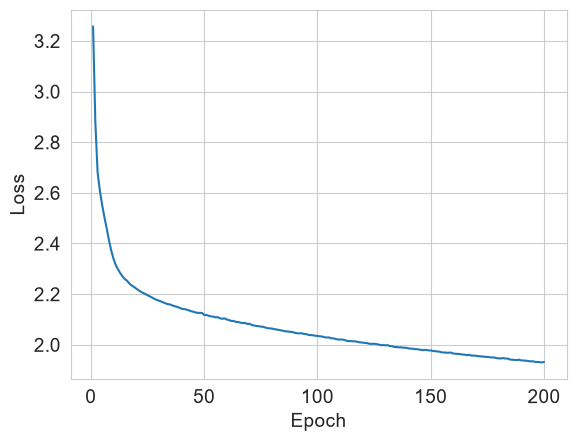

In [15]:
losses = []
num_epochs = 200
for epoch in tqdm(range(1, num_epochs + 1)):
    running_loss = 0.0
    for tokens, lengths in dataloader:
        optimizer.zero_grad()
        tokens = tokens[:, :lengths.max()].to(device)
        logits = model(tokens[:, :-1], lengths - 1)
        loss = criterion(logits.transpose(1, 2), tokens[:, 1:])
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * tokens.shape[0]

    losses += [running_loss / len(dataset)]

    if epoch % 10 == 0:
        plot_losses(losses)

In [16]:
[model.inference('') for _ in range(10)]

['narithar',
 'yrendial',
 'gandarnar',
 'tanyvh',
 'shanaevhil',
 'damskar',
 'bymfar',
 'eryllespery',
 'tathala',
 'elithann']

In [17]:
[model.inference('st') for _ in range(10)]

['stirelithel',
 'starglarie',
 'stincya',
 'starel',
 'starnavh',
 'staralvea',
 'strian',
 'starth',
 'striilan',
 'steruthai']

<h2>Анализ настроений с помощью LSTM

In [37]:
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from nltk.corpus import stopwords
from collections import Counter
import string
import re
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

In [ ]:
base_csv = 'D:/MIREA/DPO/Learning/Datasets/IMDB/IMDB Dataset.csv'
df = pd.read_csv(base_csv)
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


<h3>Формирование обучающих и тестовых данных

In [ ]:
X, y = df['review'].values, df['sentiment'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y)
# Стратификация - чтоб в каждой выборке было по каждому примеру y
print(f'Shape of train data is {X_train.shape}')
print(f'Shape of test data is {X_test.shape}')

Shape of train data is (37500,)
Shape of test data is (12500,)


<h3>Токенизация

In [27]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nuyki\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [33]:
def preprocess_string(s):
    s = re.sub(r'[^\w\s]', '', s)
    s = re.sub(r'\s+', '', s)
    s = re.sub(r'\d', '', s)
    return s

def padding_(sentences, seq_len):
    features = np.zeros((len(sentences), seq_len), dtype=int)
    for ii, review in enumerate(sentences):
        if len(review) != 0:
            features[ii, -len(review):] = np.array(review)[:seq_len]
    return features

def tokenize(X_train, y_train, X_test, y_test):
    word_list = []
    stop_words = set(stopwords.words('english'))
    for sent in X_train:
        for word in sent.lower().split():
            word = preprocess_string(word)
            if word not in stop_words and word != '':
                word_list.append(word)

    corpora = Counter(word_list)
    corpora_ = sorted(corpora, key=corpora.get, reverse=True)[:1000]
    onehot_dict = {w: i + 1 for i, w in enumerate(corpora_)}

    final_list_train, final_list_test = [], []
    for sent in X_train:
        final_list_train.append([onehot_dict[preprocess_string(word)] for word in
                                 sent.lower().split() if preprocess_string(word) in onehot_dict.keys()])
    for sent in X_test:
        final_list_test.append([onehot_dict[preprocess_string(word)] for word in
                                 sent.lower().split() if preprocess_string(word) in onehot_dict.keys()])
        
    encoded_train = [1 if label == 'positive' else 0 for label in y_train]
    encoded_test = [1 if label == 'positive' else 0 for label in y_test]

    X_train_pad = padding_(final_list_train, 500)
    X_test_pad = padding_(final_list_test, 500)

    return X_train_pad, np.array(encoded_train), X_test_pad, np.array(encoded_test), onehot_dict


In [35]:
X_train, y_train, X_test, y_test, vocab = tokenize(X_train, y_train, X_test, y_test)

In [36]:
print(f'Length of vocabulary is {len(vocab)}')

Length of vocabulary is 1000


In [55]:
train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
valid_dataset = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

BATCH_SIZE = 50

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=True)


In [56]:
sample_x, sample_y = next(iter(train_loader))

print('Sample input size: ', sample_x.size())
print('Sample input: \n', sample_x)
print('Sample input: \n', sample_y)
print('Sample input size: ', sample_y.size())

Sample input size:  torch.Size([50, 500])
Sample input: 
 tensor([[  0,   0,   0,  ...,  68,   1, 174],
        [  0,   0,   0,  ..., 114,   1, 736],
        [  0,   0,   0,  ...,  11, 167, 362],
        ...,
        [  0,   0,   0,  ..., 350, 112, 387],
        [  0,   0,   0,  ...,  36,   3, 260],
        [  0,   0,   0,  ..., 423,   3, 809]])
Sample input: 
 tensor([0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
        1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0,
        1, 1])
Sample input size:  torch.Size([50])


<h3>Архитектура модели

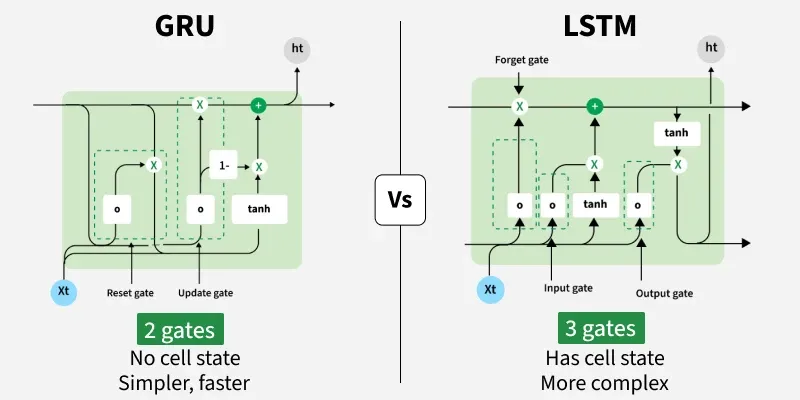

In [77]:
class SentimentRNN(nn.Module):
    def __init__(self, no_layers, vocab_size, hidden_dim,
                 output_dim, embedding_dim, drop_prob=.3):
        super(SentimentRNN, self).__init__()
        self.output_dim = output_dim
        self.hidden_dim = hidden_dim
        self.embedding_dim = embedding_dim
        self.no_layers = no_layers
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim,
                            num_layers=no_layers, batch_first=True)
        self.dropout = nn.Dropout(drop_prob)
        self.fc = nn.Linear(self.hidden_dim, self.output_dim)
        self.sig = nn.Sigmoid()

    def forward(self, x, hidden):
        batch_size = x.size(0)
        embeds = self.embedding(x)
        lstm_out, hidden = self.lstm(embeds, hidden)
        lstm_out = lstm_out.contiguous().view(-1, self.hidden_dim)
        out = self.dropout(lstm_out)
        out = self.fc(out)
        sig_out = self.sig(out)
        sig_out = sig_out.view(batch_size, -1)
        sig_out = sig_out[:, -1]
        return sig_out, hidden
    
    def init_hidden(self, batch_size):
        h0 = torch.zeros((self.no_layers, batch_size, self.hidden_dim)).to(device)
        c0 = torch.zeros((self.no_layers, batch_size, self.hidden_dim)).to(device)
        hidden = (h0, c0)
        return hidden

In [78]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [79]:
no_layers = 2
vocab_size = len(vocab) + 1
embedding_dim = 64
output_dim = 1
hidden_dim = 256

model = SentimentRNN(no_layers, vocab_size, hidden_dim,
                     output_dim, embedding_dim, drop_prob=.3).to(device)


In [80]:
print('Model size: ', sum(p.numel() for p in model.parameters()))
model.embedding

Model size:  920385


Embedding(1001, 64)

<h3>Обучение сети

In [ ]:
lr = 1e-3
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

clip = 5
num_epochs = 5
valid_loss_min = np.inf

def acc(pred, label):
    pred = torch.round(pred.squeeze())
    return torch.sum(pred == label.squeeze()).item()

def train_RNN(model, criterion, optimizer, num_epochs, clip, batch_size,
              train_loader, valid_loader, device):
    train_losses_epochs = [0.0 for i in range(num_epochs)]
    train_acc_epochs = [0.0 for i in range(num_epochs)]
    valid_losses_epochs = [0.0 for i in range(num_epochs)]
    valid_acc_epochs = [0.0 for i in range(num_epochs)]
    for epoch in tqdm(range(num_epochs)):
        train_losses = []
        train_acc = 0.0
        model.train()
        h = model.init_hidden(batch_size)
        for inputs, labels in tqdm(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)
            h = tuple([each.data for each in h])
            model.zero_grad()
            outputs, h = model(inputs, h)
            loss = criterion(outputs.squeeze(), labels.float())
            loss.backward()
            train_losses.append(loss.item())
            accuracy = acc(outputs, labels)
            train_acc += accuracy
            nn.utils.clip_grad_norm(model.parameters(), clip)
            optimizer.step()
        
        with torch.inference_mode():
            val_h = model.init_hidden(batch_size)
            val_losses = []
            val_acc = 0.0
            model.eval()
            for inputs, labels in tqdm(valid_loader):
                inputs, labels = inputs.to(device), labels.to(device)
                val_h = tuple([each.data for each in val_h])
                outputs, val_h = model(inputs, val_h)
                val_loss = criterion(outputs.squeeze(), labels.float())
                val_losses.append(val_loss.item())
                accuracy = acc(outputs, labels)
                val_acc += accuracy
        

        train_losses_epochs[epoch] = np.mean(train_losses)
        train_acc_epochs[epoch] = np.mean(val_losses)
        valid_losses_epochs[epoch] = train_acc / len(train_loader.dataset)
        valid_acc_epochs[epoch] = val_acc / len(valid_loader.dataset)

        print(f'Epoch: {epoch + 1}')
        print(f'Train Loss: {train_losses_epochs[epoch]}, Valid Loss: {valid_losses_epochs[epoch]}')
        print(f'Train Acc: {train_acc_epochs[epoch]}, Valid Acc: {valid_acc_epochs[epoch]}')
        print(25 * '==')
    return train_losses_epochs, train_acc_epochs, valid_losses_epochs, valid_acc_epochs

In [82]:
train_losses_epochs, train_acc_epochs, valid_losses_epochs, valid_acc_epochs = train_RNN(model, criterion, optimizer, num_epochs, clip,
                                                                                         BATCH_SIZE, train_loader, valid_loader, device)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/750 [00:00<?, ?it/s]

C:\Users\nuyki\AppData\Local\Temp\ipykernel_19712\2444282238.py:34: FutureWarning: `torch.nn.utils.clip_grad_norm` is now deprecated in favor of `torch.nn.utils.clip_grad_norm_`.
  nn.utils.clip_grad_norm(model.parameters(), clip)


  0%|          | 0/250 [00:00<?, ?it/s]

Epoch: 1
Train Loss: 0.5205069365104039, Valid Loss: 0.7458933333333333
Train Acc: 0.42566331511735916, Valid Acc: 0.81224


...

  0%|          | 0/250 [00:00<?, ?it/s]

Epoch: 4
Train Loss: 0.3115165065228939, Valid Loss: 0.8681866666666667
Train Acc: 0.344323476344347, Valid Acc: 0.85584


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

Epoch: 5
Train Loss: 0.28714382205406824, Valid Loss: 0.8796
Train Acc: 0.33727352344989775, Valid Acc: 0.85672


<h1><center>Практическое задание</h1></center>

1. Обучить модель анализа настроение с помощью GRU